# Evidencia 2 — Estadística del corpus y modelo de lenguaje de n-gramas

**Proyecto:** SONORA · **Materia:** Procesamiento de Lenguaje Natural · **Requisitos:** E2-01 … E2-05 (`docs/REQUIREMENTS.md` v1.2)

**Universo:** el corpus **completo** `lyrics_full_v1` (3 155 772 letras canónicas en inglés).
Las métricas descriptivas (secciones 1–6) usan **todas** las letras; el modelo de lenguaje
(sección 7) **aprende sólo con `train`** y se evalúa en `validation`; `test` no se usa aquí
(queda reservado para la evaluación final). Cuando una celda muestra ejemplos de una muestra lo
declara.

**Unidad de conteo («token» en E2).** Palabra regex `regex-words-v1`: secuencias máximas de
letras Unicode con apóstrofos internos (`don't`, `y'all` = 1 token), en minúsculas, sobre la vista
de análisis (sin anotaciones editoriales entre corchetes). Números y puntuación no son palabras.
No es la tokenización de spaCy (que separa `do` + `n't`); spaCy se usa sólo para el POS que define
los vocablos (sección 3).

**Frontera de n-gramas:** el verso. Ningún bigrama/trigrama cruza un salto de línea; los
marcadores `<s>`/`</s>` existen sólo en los conteos de `train` para el modelo de lenguaje y se
excluyen de todas las tablas descriptivas.

| Etapa | Comando | Salida |
|---|---|---|
| Conteo de n-gramas 1–3 por split | `pipelines/nlp/count_ngrams.py` | `data/processed/nlp/lyrics_full_v1/ngrams/counts` |
| Léxico POS (spaCy) por split | `pipelines/nlp/e2_frequency.py pos-lexicon` | `frequency/word_pos.parquet`, `group_pos.parquet` |
| Candidatos a vocablo (sólo train) | `pipelines/nlp/e2_frequency.py vocable-candidates` | `frequency/vocable_candidates.json` → revisión → `config/vocables.yaml` |
| Unigramas por tag y década | `pipelines/nlp/e2_frequency.py group-unigrams` | `frequency/group_unigrams/group_unigrams.parquet` |
| Resumen de n-gramas (totales, espectro, top-K) | `pipelines/nlp/e2_frequency.py ngram-summary` | `frequency/ngram_summary.json` |
| Vocabulario y texto del modelo | `pipelines/nlp/e2_frequency.py lm-vocab` / `lm-export` | `lm/vocab_train_min2.txt`, `lm/text/shards/` |
| KenLM (WSL) | `scripts/kenlm/build_kenlm.sh`; `pipelines/nlp/ngram_lm.py train/eval` | `lm/results.json` |

In [1]:
import json, math, sys
from collections import Counter
from pathlib import Path
import numpy as np
import pyarrow as pa, pyarrow.compute as pc, pyarrow.dataset as ds, pyarrow.parquet as pq
import matplotlib.pyplot as plt
import yaml

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "packages" / "sonora" / "src"))
from sonora import viz
viz.apply_style()

RUN = "lyrics_full_v1"
NLP = ROOT / "data/processed/nlp" / RUN
FIG = ROOT / "reports/figures/E2"
S = json.loads((NLP / "frequency/ngram_summary.json").read_text(encoding="utf-8"))
O = S["orders"]
manifest = json.loads((ROOT / "manifests/nlp" / f"{RUN}.json").read_text(encoding="utf-8"))
lex = pq.read_table(NLP / "lexicon/lexicon.parquet")
lex_count = dict(zip(lex["word"].to_pylist(), lex["count"].to_pylist()))
VOC = yaml.safe_load((ROOT / "config/vocables.yaml").read_text(encoding="utf-8"))
VOCABLES = set(VOC["vocables"])
from spacy.lang.en.stop_words import STOP_WORDS
from sonora.nlp.frequency import function_words
STOP_SPACY = {w.lower() for w in STOP_WORDS}
STOP = function_words(STOP_SPACY, lex["word"].to_pylist())  # + contracciones funcionales (i'm, don't)

def fmt(n): return f"{n:,}".replace(",", " ")
def show(rows, cols=None):
    from IPython.display import Markdown, display
    cols = cols or list(rows[0])
    def cell(v):
        if isinstance(v, float): return f"{v:,.3f}".replace(",", " ")
        if isinstance(v, (int, np.integer)): return fmt(int(v))
        return str(v)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    lines += ["| " + " | ".join(cell(r[c]) for c in cols) + " |" for r in rows]
    display(Markdown("\n".join(lines)))
print("Resumen de n-gramas:", S["version"], "|", S["partitions"], "particiones |", S["note"])
print("Stopwords spaCy:", len(STOP_SPACY), "| + contracciones funcionales del léxico:", len(STOP - STOP_SPACY),
      "| vocablos:", len(VOCABLES), f"({VOC['version']})")
print("Ejemplos de contracciones añadidas:", ", ".join(sorted(STOP - STOP_SPACY, key=lambda w: -int(lex_count.get(w, 0)))[:15]))

Resumen de n-gramas: frequency-v1 | 256 particiones | descriptive: n-grams with <s>/</s> removed; within-verse n-grams only
Stopwords spaCy: 326 | + contracciones funcionales del léxico: 807 | vocablos: 424 (vocables-v1)
Ejemplos de contracciones añadidas: i'm, don't, it's, can't, ain't, you're, i'll, that's, i've, won't, there's, we're, you'll, what's, i'd


## 1. Universo de tokens y reconciliación (E2-01)

Antes de interpretar, los totales del resumen de n-gramas deben coincidir con el léxico
construido de forma independiente (`annotate_corpus.py lexicon`) y con el manifiesto del conteo.

In [2]:
lex_tokens = int(pc.sum(lex["count"]).as_py())
ng_summary = json.loads((NLP / "ngrams/summary.json").read_text(encoding="utf-8"))
rows = []
for scope in ("all", "train", "validation", "test"):
    u = O["1"][scope]
    ref = lex_tokens if scope == "all" else ng_summary["totals_by_split"][scope]["tokens"]
    rows.append({"alcance": scope, "tokens (unigramas)": u["tokens"], "tipos": u["types"],
                 "referencia": ref, "coincide": "sí" if u["tokens"] == ref else "NO"})
show(rows)
assert all(r["coincide"] == "sí" for r in rows)
assert O["1"]["all"]["types"] == lex.num_rows
N = O["1"]["all"]["tokens"]
print(f"Universo: {fmt(N)} tokens, {fmt(O['1']['all']['types'])} tipos, {fmt(lex.num_rows)} filas del léxico.")

| alcance | tokens (unigramas) | tipos | referencia | coincide |
|---|---|---|---|---|
| all | 902 376 353 | 1 277 145 | 902 376 353 | sí |
| train | 631 669 490 | 1 027 340 | 631 669 490 | sí |
| validation | 90 048 892 | 318 297 | 90 048 892 | sí |
| test | 180 657 971 | 482 111 | 180 657 971 | sí |

Universo: 902 376 353 tokens, 1 277 145 tipos, 1 277 145 filas del léxico.


## 2. Frecuencias absolutas y relativas con y sin palabras funcionales (E2-01)

Tres políticas sobre el **mismo** universo de tokens: (a) todas las palabras; (b) sin las 326
*stopwords* de spaCy 3.8 (palabras funcionales y algunos adverbios frecuentes) **más las
contracciones formadas sólo por ellas** (`i'm`, `don't`, `it's`: el tokenizador regex no las separa
y la lista de spaCy sólo contiene las piezas `'m`, `n't`); (c) sin
stopwords ni vocablos/muletillas (sección 3). La frecuencia relativa se expresa por millón de
tokens del universo completo, de modo que las tres columnas son comparables.

La comparación se justifica porque (a) mide la distribución real (base de Zipf y del modelo de
lenguaje), mientras (b) y (c) revelan el contenido temático que las palabras funcionales y los
vocablos ocultan en el top.

In [3]:
words = lex["word"].to_pylist(); counts = lex["count"].to_numpy(); dfreq = lex["doc_freq"].to_numpy()
is_stop = np.array([w in STOP for w in words]); is_voc = np.array([w in VOCABLES for w in words])
D = 3155772
def top(mask, k=25):
    idx = np.flatnonzero(mask)[:k]  # el léxico ya está ordenado por frecuencia descendente
    cum = 0; out = []
    for r, i in enumerate(idx, 1):
        cum += counts[i]
        out.append({"rango": r, "palabra": words[i], "frecuencia": int(counts[i]),
                    "por millón": 1e6 * counts[i] / N, "% acumulado": 100 * cum / N,
                    "% de letras": 100 * dfreq[i] / D})
    return out
pol = {"a) todas": np.ones(len(words), bool), "b) sin stopwords": ~is_stop, "c) sin stopwords ni vocablos": ~is_stop & ~is_voc}
for name, m in pol.items():
    print(name); show(top(m, 20))
show([{"política": n, "tokens que quedan": int(counts[m].sum()), "% del universo": 100 * counts[m].sum() / N,
       "tipos": int(m.sum())} for n, m in pol.items()])

a) todas


| rango | palabra | frecuencia | por millón | % acumulado | % de letras |
|---|---|---|---|---|---|
| 1 | the | 33 561 503 | 37 192.356 | 3.719 | 95.156 |
| 2 | i | 33 215 499 | 36 808.920 | 7.400 | 87.604 |
| 3 | you | 27 479 421 | 30 452.284 | 10.445 | 85.680 |
| 4 | to | 18 143 568 | 20 106.431 | 12.456 | 90.024 |
| 5 | a | 18 094 127 | 20 051.641 | 14.461 | 84.647 |
| 6 | and | 17 239 983 | 19 105.092 | 16.372 | 87.777 |
| 7 | my | 14 392 176 | 15 949.195 | 17.967 | 75.130 |
| 8 | me | 13 966 279 | 15 477.222 | 19.514 | 74.836 |
| 9 | in | 11 704 180 | 12 970.398 | 20.811 | 80.889 |
| 10 | it | 11 624 714 | 12 882.334 | 22.100 | 71.205 |
| 11 | i'm | 10 030 814 | 11 115.998 | 23.211 | 59.604 |
| 12 | that | 8 834 926 | 9 790.733 | 24.190 | 68.278 |
| 13 | on | 8 642 829 | 9 577.854 | 25.148 | 66.874 |
| 14 | of | 8 406 547 | 9 316.010 | 26.080 | 70.286 |
| 15 | your | 7 512 650 | 8 325.407 | 26.912 | 60.075 |
| 16 | like | 6 678 567 | 7 401.088 | 27.652 | 53.940 |
| 17 | all | 6 563 386 | 7 273.446 | 28.380 | 63.450 |
| 18 | we | 6 356 405 | 7 044.073 | 29.084 | 47.071 |
| 19 | is | 6 215 693 | 6 888.138 | 29.773 | 59.874 |
| 20 | for | 6 160 706 | 6 827.202 | 30.456 | 60.758 |

b) sin stopwords


| rango | palabra | frecuencia | por millón | % acumulado | % de letras |
|---|---|---|---|---|---|
| 1 | like | 6 678 567 | 7 401.088 | 0.740 | 53.940 |
| 2 | know | 5 383 100 | 5 965.471 | 1.337 | 51.807 |
| 3 | got | 4 363 197 | 4 835.230 | 1.820 | 40.749 |
| 4 | yeah | 3 977 078 | 4 407.338 | 2.261 | 26.845 |
| 5 | love | 3 828 765 | 4 242.980 | 2.685 | 33.787 |
| 6 | oh | 3 262 694 | 3 615.669 | 3.047 | 23.895 |
| 7 | time | 2 715 313 | 3 009.069 | 3.348 | 36.532 |
| 8 | want | 2 317 028 | 2 567.696 | 3.604 | 27.226 |
| 9 | cause | 2 183 344 | 2 419.549 | 3.846 | 28.602 |
| 10 | wanna | 2 049 306 | 2 271.010 | 4.074 | 21.674 |
| 11 | way | 1 960 003 | 2 172.046 | 4.291 | 28.039 |
| 12 | let | 1 937 179 | 2 146.753 | 4.505 | 24.741 |
| 13 | come | 1 896 337 | 2 101.492 | 4.716 | 25.853 |
| 14 | feel | 1 867 632 | 2 069.682 | 4.923 | 25.765 |
| 15 | need | 1 828 537 | 2 026.357 | 5.125 | 24.148 |
| 16 | baby | 1 816 980 | 2 013.550 | 5.326 | 16.597 |
| 17 | life | 1 757 459 | 1 947.590 | 5.521 | 25.548 |
| 18 | shit | 1 749 228 | 1 938.468 | 5.715 | 18.580 |
| 19 | fuck | 1 603 266 | 1 776.715 | 5.893 | 17.010 |
| 20 | right | 1 575 676 | 1 746.141 | 6.067 | 23.011 |

c) sin stopwords ni vocablos


| rango | palabra | frecuencia | por millón | % acumulado | % de letras |
|---|---|---|---|---|---|
| 1 | like | 6 678 567 | 7 401.088 | 0.740 | 53.940 |
| 2 | know | 5 383 100 | 5 965.471 | 1.337 | 51.807 |
| 3 | got | 4 363 197 | 4 835.230 | 1.820 | 40.749 |
| 4 | love | 3 828 765 | 4 242.980 | 2.244 | 33.787 |
| 5 | time | 2 715 313 | 3 009.069 | 2.545 | 36.532 |
| 6 | want | 2 317 028 | 2 567.696 | 2.802 | 27.226 |
| 7 | cause | 2 183 344 | 2 419.549 | 3.044 | 28.602 |
| 8 | wanna | 2 049 306 | 2 271.010 | 3.271 | 21.674 |
| 9 | way | 1 960 003 | 2 172.046 | 3.488 | 28.039 |
| 10 | let | 1 937 179 | 2 146.753 | 3.703 | 24.741 |
| 11 | come | 1 896 337 | 2 101.492 | 3.913 | 25.853 |
| 12 | feel | 1 867 632 | 2 069.682 | 4.120 | 25.765 |
| 13 | need | 1 828 537 | 2 026.357 | 4.323 | 24.148 |
| 14 | baby | 1 816 980 | 2 013.550 | 4.524 | 16.597 |
| 15 | life | 1 757 459 | 1 947.590 | 4.719 | 25.548 |
| 16 | shit | 1 749 228 | 1 938.468 | 4.913 | 18.580 |
| 17 | fuck | 1 603 266 | 1 776.715 | 5.090 | 17.010 |
| 18 | right | 1 575 676 | 1 746.141 | 5.265 | 23.011 |
| 19 | bitch | 1 536 446 | 1 702.667 | 5.435 | 12.975 |
| 20 | tell | 1 516 514 | 1 680.578 | 5.603 | 21.802 |

| política | tokens que quedan | % del universo | tipos |
|---|---|---|---|
| a) todas | 902 376 353 | 100.000 | 1 277 145 |
| b) sin stopwords | 391 545 121 | 43.390 | 1 276 033 |
| c) sin stopwords ni vocablos | 376 102 627 | 41.679 | 1 275 609 |

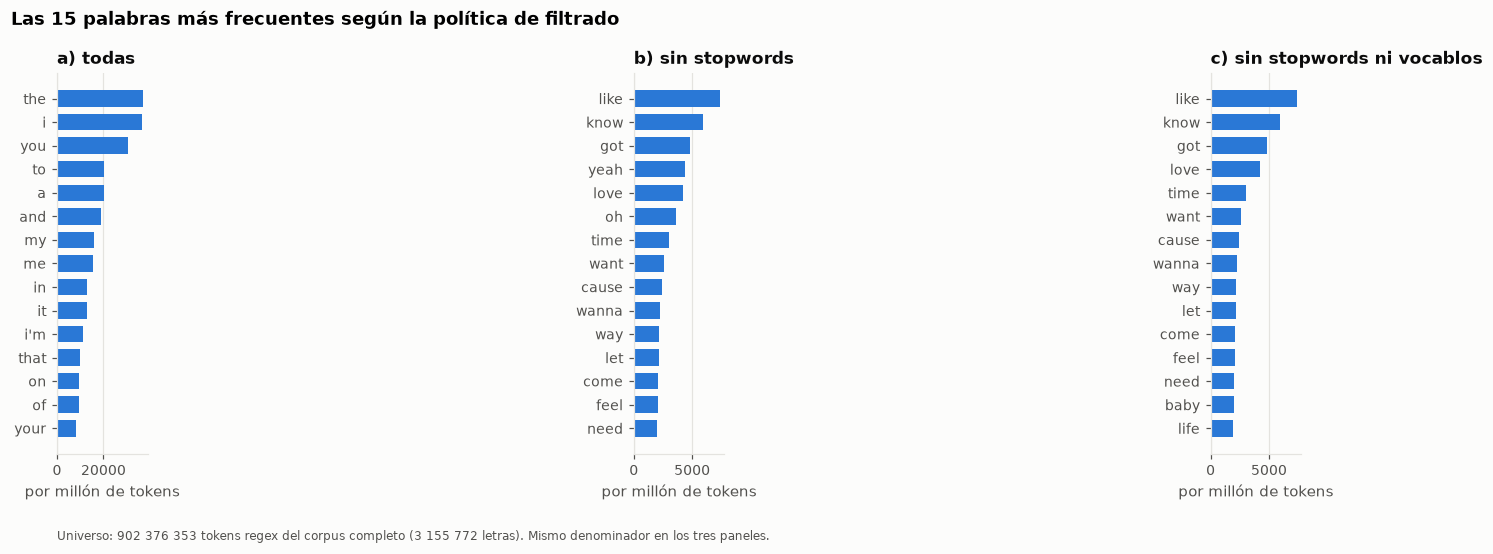

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5.2), sharex=False)
for ax, (name, m) in zip(axes, pol.items()):
    t = top(m, 15)[::-1]
    ax.barh([r["palabra"] for r in t], [r["por millón"] for r in t], color=viz.SEQUENTIAL, height=0.7)
    ax.set_title(name, fontsize=11); ax.set_xlabel("por millón de tokens")
    ax.grid(axis="y", visible=False)
fig.suptitle("Las 15 palabras más frecuentes según la política de filtrado", x=0.01, ha="left", fontweight="bold")
viz.caption(axes[0], f"Universo: {fmt(N)} tokens regex del corpus completo (3 155 772 letras). Mismo denominador en los tres paneles.")
fig.tight_layout(); viz.save(fig, FIG / "e2_top_palabras_politicas.png"); plt.show()

## 3. Vocablos y muletillas: lista derivada de los datos (E2-01)

Un *vocablo* es una palabra no léxica de relleno o expresión (`oh`, `yeah`, `na`, `ooh`). La
lista no se escribió a mano: se derivó **sólo de `train`** con dos criterios y luego se revisó.

1. **POS mayoritario `INTJ`** en la anotación spaCy de `train` (forma en minúsculas, ≥ 100
   apariciones);
2. **patrón de sílabas**: una sílaba corta repetida (`nana`, `lalala`) o una letra alargada
   tres o más veces (`ooooh`), con ≥ 100 apariciones.

La revisión excluye interjecciones con contenido léxico (saludos, cortesía, insultos, `yes`/`no`)
y registra cada exclusión con su motivo en `config/vocables.yaml`.

In [5]:
cand = json.loads((NLP / "frequency/vocable_candidates.json").read_text(encoding="utf-8"))
reasons = Counter(r for c in cand for r in c["reasons"])
print(f"Candidatos (train, ≥100): {len(cand)} | por criterio: {dict(reasons)}")
print(f"Lista final: {len(VOCABLES)} vocablos | excluidos en revisión: {len(VOC['excluded'])}")
show([{"forma": c["form"], "frecuencia train": c["count"], "POS mayoritario": c["majority_upos"],
       "% INTJ": 100 * c["intj_share"], "criterio": ", ".join(c["reasons"]),
       "decisión": "vocablo" if c["form"] in VOCABLES else ("excluido en revisión: " + VOC["excluded"][c["form"]]
                  if c["form"] in VOC["excluded"] else "no admitido: sólo patrón y su reducción no es vocablo")}
      for c in cand[:40]])
voc_tokens = int(counts[is_voc].sum())
print(f"Los vocablos suman {fmt(voc_tokens)} tokens ({100*voc_tokens/N:.2f} % del universo completo).")

Candidatos (train, ≥100): 731 | por criterio: {'intj_majority': 42, 'self_repetition': 184, 'repeated_syllable': 167, 'elongated': 387}
Lista final: 424 vocablos | excluidos en revisión: 90


| forma | frecuencia train | POS mayoritario | % INTJ | criterio | decisión |
|---|---|---|---|---|---|
| yeah | 2 784 994 | INTJ | 93.550 | intj_majority | vocablo |
| oh | 2 284 898 | INTJ | 96.320 | intj_majority, self_repetition | vocablo |
| ooh | 529 998 | PROPN | 34.750 | self_repetition | vocablo |
| well | 519 139 | INTJ | 66.720 | intj_majority | excluido en revisión: adverbio y marcador discursivo léxico (además es stopword) |
| hey | 452 490 | INTJ | 87.460 | intj_majority, self_repetition | vocablo |
| uh | 452 021 | INTJ | 99.810 | intj_majority | vocablo |
| la | 410 426 | PROPN | 14.430 | self_repetition | vocablo |
| please | 361 066 | INTJ | 91.840 | intj_majority | excluido en revisión: cortesía, contenido léxico |
| ah | 327 656 | INTJ | 96.330 | intj_majority, self_repetition | vocablo |
| na | 293 529 | PART | 1.150 | self_repetition | vocablo |
| damn | 271 815 | INTJ | 23.270 | intj_majority | excluido en revisión: expletivo con contenido léxico |
| da | 234 224 | PROPN | 1.040 | self_repetition | vocablo |
| yes | 230 747 | INTJ | 95.950 | intj_majority | excluido en revisión: afirmación léxica |
| woah | 177 105 | PROPN | 33.780 | self_repetition | vocablo |
| nah | 166 233 | PROPN | 34.260 | self_repetition | vocablo |
| ay | 139 253 | PROPN | 30.510 | self_repetition | vocablo |
| ha | 132 152 | INTJ | 87.580 | intj_majority, self_repetition | vocablo |
| mama | 130 468 | PROPN | 0.710 | repeated_syllable | no admitido: sólo patrón y su reducción no es vocablo |
| whoa | 126 374 | INTJ | 34.190 | intj_majority, self_repetition | vocablo |
| bang | 93 064 | PROPN | 0.000 | self_repetition | excluido en revisión: onomatopeya léxica (verbo/sustantivo) |
| boom | 72 222 | NOUN | 0.000 | self_repetition | excluido en revisión: onomatopeya léxica |
| doo | 67 840 | PROPN | 3.300 | self_repetition | vocablo |
| eh | 66 970 | INTJ | 87.180 | intj_majority, self_repetition | vocablo |
| yah | 66 731 | PROPN | 26.460 | self_repetition | vocablo |
| ba | 66 194 | PROPN | 0.150 | self_repetition | vocablo |
| hello | 62 348 | INTJ | 74.470 | intj_majority | excluido en revisión: saludo léxico |
| bye | 57 959 | INTJ | 46.720 | intj_majority, self_repetition | excluido en revisión: despedida léxica |
| mmm | 47 900 | PROPN | 1.860 | elongated, self_repetition | vocablo |
| oooh | 46 162 | PROPN | 0.170 | elongated | vocablo |
| ahh | 42 496 | PROPN | 0.000 | self_repetition | vocablo |
| oo | 41 929 | NOUN | 15.880 | repeated_syllable, self_repetition | vocablo |
| mm | 40 948 | PROPN | 9.920 | self_repetition | vocablo |
| wow | 36 909 | INTJ | 77.860 | intj_majority | vocablo |
| ooo | 36 776 | PROPN | 0.730 | repeated_syllable, elongated | vocablo |
| hmm | 31 917 | INTJ | 44.690 | intj_majority, self_repetition | vocablo |
| hi | 31 422 | INTJ | 53.410 | intj_majority | excluido en revisión: saludo léxico |
| hoo | 30 827 | PROPN | 0.120 | self_repetition | vocablo |
| haha | 27 501 | PROPN | 8.470 | repeated_syllable | vocablo |
| lo | 26 644 | PROPN | 0.730 | self_repetition | excluido en revisión: pronombre español / inglés arcaico (ambiguo) |
| ey | 26 556 | PROPN | 1.600 | self_repetition | vocablo |

Los vocablos suman 15 442 494 tokens (1.71 % del universo completo).


In [6]:
# Peso de los vocablos por tag (corpus completo; tokens regex; denominador = tokens del tag).
gu = pq.read_table(NLP / "frequency/group_unigrams/group_unigrams.parquet")
tg = gu.filter(pc.equal(gu["kind"], "tag"))
by = {}
for g, w, c in zip(tg["group"].to_pylist(), tg["word"].to_pylist(), tg["count"].to_pylist()):
    b = by.setdefault(g, [0, 0, 0]); b[0] += c
    if w in VOCABLES: b[1] += c
    if w in STOP: b[2] += c
show([{"tag": t, "tokens": by[t][0], "vocablos por 1000": 1000 * by[t][1] / by[t][0],
       "stopwords %": 100 * by[t][2] / by[t][0]} for t in viz.TAG_ORDER])
assert sum(v[0] for v in by.values()) == N

| tag | tokens | vocablos por 1000 | stopwords % |
|---|---|---|---|
| pop | 300 931 247 | 19.477 | 58.873 |
| rap | 411 417 047 | 15.586 | 53.960 |
| rock | 124 275 048 | 12.652 | 58.589 |
| rb | 46 414 365 | 29.193 | 59.193 |
| country | 19 338 646 | 12.499 | 58.849 |

## 4. n-gramas (E2-02)

Reglas: tokens regex en minúsculas; bigramas y trigramas **dentro del verso**; sin marcadores;
conteos sobre el corpus completo (suma de los tres splits). El filtro «contenido» elimina todo
n-grama que contenga al menos una stopword o un vocablo.

In [7]:
rows = []
for o in ("1", "2", "3"):
    a = O[o]["all"]; sp = a["spectrum_le1000"]
    rows.append({"orden": int(o), "ocurrencias": a["tokens"], "tipos": a["types"],
                 "hapax (f=1)": sp.get("1", 0), "% tipos hapax": 100 * sp.get("1", 0) / a["types"],
                 "tipos/ocurrencias": a["types"] / a["tokens"]})
show(rows)
def ngram_table(order, key, k=20):
    t = O[order]["all"][key][:k]
    tot = O[order]["all"]["tokens"]
    return [{"rango": i, "n-grama": g, "frecuencia": c, "por millón": 1e6 * c / tot} for i, (g, c) in enumerate(t, 1)]
for o, name in (("2", "Bigramas"), ("3", "Trigramas")):
    print(name, "— todos"); show(ngram_table(o, "top"))
    print(name, "— contenido (sin stopwords ni vocablos)"); show(ngram_table(o, "top_content"))

| orden | ocurrencias | tipos | hapax (f=1) | % tipos hapax | tipos/ocurrencias |
|---|---|---|---|---|---|
| 1 | 902 376 353 | 1 277 145 | 659 589 | 51.646 | 0.001 |
| 2 | 771 323 850 | 25 877 889 | 15 043 878 | 58.134 | 0.034 |
| 3 | 643 678 822 | 105 251 805 | 70 245 738 | 66.741 | 0.164 |

Bigramas — todos


| rango | n-grama | frecuencia | por millón |
|---|---|---|---|
| 1 | in the | 3 439 666 | 4 459.432 |
| 2 | i don't | 2 132 565 | 2 764.811 |
| 3 | on the | 1 876 764 | 2 433.173 |
| 4 | and i | 1 825 844 | 2 367.156 |
| 5 | i know | 1 589 714 | 2 061.020 |
| 6 | to the | 1 551 611 | 2 011.621 |
| 7 | you know | 1 410 830 | 1 829.102 |
| 8 | in my | 1 405 614 | 1 822.340 |
| 9 | like a | 1 270 831 | 1 647.597 |
| 10 | of the | 1 266 657 | 1 642.186 |
| 11 | i got | 1 266 238 | 1 641.642 |
| 12 | on my | 1 146 136 | 1 485.934 |
| 13 | if you | 1 104 136 | 1 431.482 |
| 14 | to be | 1 100 713 | 1 427.044 |
| 15 | i can't | 1 096 086 | 1 421.045 |
| 16 | but i | 1 075 869 | 1 394.834 |
| 17 | that i | 1 036 547 | 1 343.854 |
| 18 | when i | 977 762 | 1 267.641 |
| 19 | for the | 977 684 | 1 267.540 |
| 20 | i was | 958 196 | 1 242.275 |

Bigramas — contenido (sin stopwords ni vocablos)


| rango | n-grama | frecuencia | por millón |
|---|---|---|---|
| 1 | feel like | 328 820 | 426.306 |
| 2 | feels like | 104 704 | 135.746 |
| 3 | wanna know | 90 315 | 117.091 |
| 4 | look like | 89 863 | 116.505 |
| 5 | little bit | 84 896 | 110.065 |
| 6 | far away | 81 294 | 105.395 |
| 7 | feeling like | 79 114 | 102.569 |
| 8 | brand new | 75 765 | 98.227 |
| 9 | run away | 74 846 | 97.036 |
| 10 | tell em | 65 413 | 84.806 |
| 11 | love love | 63 777 | 82.685 |
| 12 | baby baby | 63 141 | 81.861 |
| 13 | act like | 61 707 | 80.001 |
| 14 | long time | 61 078 | 79.186 |
| 15 | baby girl | 58 397 | 75.710 |
| 16 | walk away | 50 225 | 65.115 |
| 17 | let em | 48 922 | 63.426 |
| 18 | new york | 47 932 | 62.143 |
| 19 | wanna fuck | 47 749 | 61.905 |
| 20 | bad bitch | 46 999 | 60.933 |

Trigramas — todos


| rango | n-grama | frecuencia | por millón |
|---|---|---|---|
| 1 | oh oh oh | 450 177 | 699.381 |
| 2 | i don't know | 377 315 | 586.185 |
| 3 | la la la | 300 696 | 467.152 |
| 4 | yeah yeah yeah | 273 249 | 424.511 |
| 5 | i don't wanna | 269 780 | 419.122 |
| 6 | na na na | 212 822 | 330.634 |
| 7 | i want to | 210 096 | 326.399 |
| 8 | i know you | 208 167 | 323.402 |
| 9 | i love you | 201 160 | 312.516 |
| 10 | i don't want | 196 973 | 306.011 |
| 11 | i know that | 196 080 | 304.624 |
| 12 | i got a | 189 407 | 294.257 |
| 13 | you know i | 181 573 | 282.086 |
| 14 | i just wanna | 169 856 | 263.883 |
| 15 | up in the | 160 824 | 249.851 |
| 16 | and i don't | 152 154 | 236.382 |
| 17 | you know that | 150 745 | 234.193 |
| 18 | i don't need | 148 651 | 230.940 |
| 19 | i feel like | 148 008 | 229.941 |
| 20 | i know i | 147 475 | 229.113 |

Trigramas — contenido (sin stopwords ni vocablos)


| rango | n-grama | frecuencia | por millón |
|---|---|---|---|
| 1 | love love love | 29 354 | 45.603 |
| 2 | baby baby baby | 18 839 | 29.268 |
| 3 | run run run | 17 489 | 27.170 |
| 4 | aye aye aye | 17 160 | 26.659 |
| 5 | o o o | 16 979 | 26.378 |
| 6 | yea yea yea | 16 381 | 25.449 |
| 7 | boom boom boom | 16 000 | 24.857 |
| 8 | rock n roll | 14 730 | 22.884 |
| 9 | ya ya ya | 13 577 | 21.093 |
| 10 | yo yo yo | 11 803 | 18.337 |
| 11 | money money money | 11 358 | 17.645 |
| 12 | gang gang gang | 11 255 | 17.485 |
| 13 | bang bang bang | 10 879 | 16.901 |
| 14 | let em know | 10 804 | 16.785 |
| 15 | bye bye bye | 9 804 | 15.231 |
| 16 | dreams come true | 9 564 | 14.858 |
| 17 | new york city | 8 895 | 13.819 |
| 18 | work work work | 8 812 | 13.690 |
| 19 | long time ago | 8 777 | 13.636 |
| 20 | dance dance dance | 8 423 | 13.086 |

In [8]:
# Ejemplos de patrones: n-gramas formados sólo por vocablos (repetición de sílabas) frente a
# n-gramas con verbo de contenido; se buscan en los top-K guardados (K = 2000 por orden).
def only_vocables(g): return all(w in VOCABLES for w in g.split())
for o in ("2", "3"):
    t = O[o]["all"]["top"]
    v = [(g, c) for g, c in t if only_vocables(g)]
    share = sum(c for _, c in v) / sum(c for _, c in t)
    print(f"Orden {o}: {len(v)} de los {len(t)} n-gramas más frecuentes son sólo vocablos "
          f"({100*share:.1f} % de sus ocurrencias). Ejemplos: {', '.join(g for g, _ in v[:8])}")
pron = [(g, c) for g, c in O["3"]["all"]["top"] if g.split()[0] in {"i", "you"}][:12]
print("Trigramas que empiezan con 'i'/'you':", "; ".join(f"{g} ({fmt(c)})" for g, c in pron))

Orden 2: 17 de los 2000 n-gramas más frecuentes son sólo vocablos (1.3 % de sus ocurrencias). Ejemplos: oh oh, yeah yeah, la la, na na, ooh ooh, oh yeah, ah ah, da da
Orden 3: 23 de los 2000 n-gramas más frecuentes son sólo vocablos (3.3 % de sus ocurrencias). Ejemplos: oh oh oh, la la la, yeah yeah yeah, na na na, ooh ooh ooh, da da da, ah ah ah, hey hey hey
Trigramas que empiezan con 'i'/'you': i don't know (377 315); i don't wanna (269 780); i want to (210 096); i know you (208 167); i love you (201 160); i don't want (196 973); i know that (196 080); i got a (189 407); you know i (181 573); i just wanna (169 856); you know that (150 745); i don't need (148 651)


## 5. Rango–frecuencia: ley de Zipf y sus desviaciones (E2-03)

Se ajusta $\log f = \log C - \alpha \log r$ por mínimos cuadrados sobre rangos espaciados
logarítmicamente (para no dar peso desmedido a la cola) en un tramo central declarado, y un
modelo de Zipf–Mandelbrot $f = C/(r+b)^{\alpha}$ (búsqueda en rejilla de $b$, mínimos cuadrados
en $\alpha$, $C$). No se presupone que la ley se cumpla: se informan $R^2$ y los residuos por
tramo.

In [9]:
def rank_freq(order, scope="all"):
    a = O[order][scope]
    hi = np.array(a.get("counts_gt1000", []), dtype=float)
    spec = {int(k): v for k, v in a["spectrum_le1000"].items()}
    fvals = np.concatenate([np.sort(np.unique(hi))[::-1], np.array(sorted(spec, reverse=True), float)])
    mult = np.concatenate([[int((hi == f).sum()) for f in np.sort(np.unique(hi))[::-1]], [spec[int(f)] for f in sorted(spec, reverse=True)]])
    return fvals, np.cumsum(mult)  # frecuencia distinta (desc.) y rango final de cada escalón
def f_at(fvals, cum, ranks):
    return fvals[np.searchsorted(cum, ranks)]
def zipf_fit(order, r_lo, r_hi, n=200):
    fv, cum = rank_freq(order)
    r = np.unique(np.logspace(np.log10(r_lo), np.log10(r_hi), n).astype(int))
    x, y = np.log10(r), np.log10(f_at(fv, cum, r))
    A = np.vstack([np.ones_like(x), x]).T
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    pred = A @ coef; r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    best = None
    for b in np.concatenate([[0], np.logspace(-1, 3, 200)]):
        xb = np.log10(r + b); Ab = np.vstack([np.ones_like(xb), xb]).T
        cb, *_ = np.linalg.lstsq(Ab, y, rcond=None); sse = ((y - Ab @ cb) ** 2).sum()
        if best is None or sse < best[0]: best = (sse, b, cb)
    return {"alpha": -coef[1], "logC": coef[0], "r2": r2, "zm_b": best[1], "zm_alpha": -best[2][1],
            "zm_r2": 1 - best[0] / ((y - y.mean()) ** 2).sum(), "ranks": r, "y": y, "pred": pred}
fits = {}
for o in ("1", "2", "3"):
    fv, cum = rank_freq(o)
    r_hi = int(cum[np.searchsorted(-fv, -10, side="right") - 1])  # último rango con f ≥ 10
    fits[o] = zipf_fit(o, 1, r_hi); fits[o]["r_hi"] = r_hi
    fits[o + "c"] = zipf_fit(o, 10, 10_000)  # tramo central clásico, igual para los tres órdenes
show([{"orden": o, "tramo de rangos": f"1–{fmt(fits[o]['r_hi'])}", "α (Zipf, desde r=1)": fits[o]["alpha"], "R²": fits[o]["r2"],
       "α (10 ≤ r ≤ 10 000)": fits[o + "c"]["alpha"], "R² central": fits[o + "c"]["r2"],
       "Zipf–Mandelbrot b": fits[o]["zm_b"], "α ZM": fits[o]["zm_alpha"], "R² ZM": fits[o]["zm_r2"]} for o in ("1", "2", "3")])
print("Tramo: rangos con frecuencia ≥ 10 (por encima, la meseta de frecuencias 1–9 es escalonada).")

| orden | tramo de rangos | α (Zipf, desde r=1) | R² | α (10 ≤ r ≤ 10 000) | R² central | Zipf–Mandelbrot b | α ZM | R² ZM |
|---|---|---|---|---|---|---|---|---|
| 1 | 1–197 878 | 1.363 | 0.978 | 1.226 | 0.992 | 39.171 | 1.605 | 0.995 |
| 2 | 1–2 580 515 | 0.926 | 0.973 | 0.738 | 0.984 | 103.532 | 1.119 | 0.996 |
| 3 | 1–5 697 757 | 0.727 | 0.974 | 0.552 | 0.991 | 113.573 | 0.868 | 0.994 |

Tramo: rangos con frecuencia ≥ 10 (por encima, la meseta de frecuencias 1–9 es escalonada).


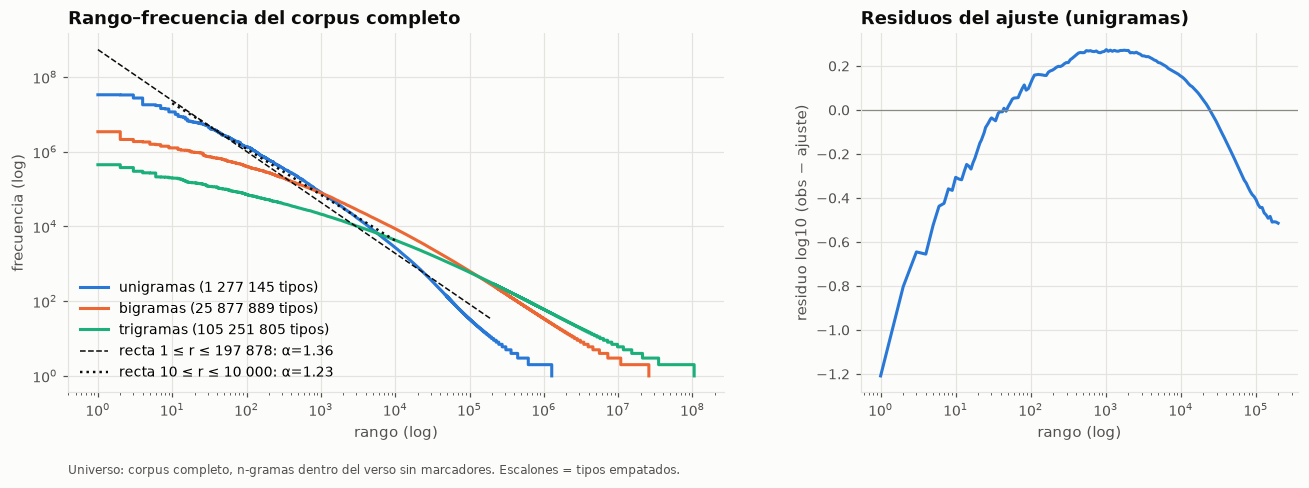

| tramo | residuo medio (log10) | factor obs/ajuste |
|---|---|---|
| r ≤ 10 | -0.573 | 0.267 |
| 10 < r ≤ 1 000 | 0.082 | 1.207 |
| 1 000 < r ≤ 100 000 | 0.074 | 1.185 |
| r > 100 000 | -0.474 | 0.336 |

In [10]:
fig, (ax, axr) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
names = {"1": "unigramas", "2": "bigramas", "3": "trigramas"}
for i, o in enumerate(("1", "2", "3")):
    fv, cum = rank_freq(o)
    ax.loglog(cum, fv, drawstyle="steps-post", color=viz.CATEGORICAL[i], label=f"{names[o]} ({fmt(int(cum[-1]))} tipos)")
f1 = fits["1"]
ax.loglog(10 ** np.log10(f1["ranks"]), 10 ** f1["pred"], color=viz.TEXT, linestyle="--", linewidth=1,
          label=f"recta 1 ≤ r ≤ {fmt(f1['r_hi'])}: α={f1['alpha']:.2f}")
fc = fits["1c"]
ax.loglog(fc["ranks"], 10 ** fc["pred"], color=viz.TEXT, linestyle=":", linewidth=1.6,
          label=f"recta 10 ≤ r ≤ 10 000: α={fc['alpha']:.2f}")
ax.set_xlabel("rango (log)"); ax.set_ylabel("frecuencia (log)"); ax.set_title("Rango–frecuencia del corpus completo")
ax.legend(loc="lower left")
viz.caption(ax, "Universo: corpus completo, n-gramas dentro del verso sin marcadores. Escalones = tipos empatados.")
axr.semilogx(f1["ranks"], f1["y"] - f1["pred"], color=viz.CATEGORICAL[0])
axr.axhline(0, color=viz.MUTED, linewidth=0.8)
axr.set_xlabel("rango (log)"); axr.set_ylabel("residuo log10 (obs − ajuste)"); axr.set_title("Residuos del ajuste (unigramas)")
fig.tight_layout(); viz.save(fig, FIG / "e2_zipf.png"); plt.show()
r = f1["ranks"]; res = f1["y"] - f1["pred"]
show([{"tramo": lab, "residuo medio (log10)": float(res[m].mean()), "factor obs/ajuste": float(10 ** res[m].mean())}
      for lab, m in (("r ≤ 10", r <= 10), ("10 < r ≤ 1 000", (r > 10) & (r <= 1000)),
                     ("1 000 < r ≤ 100 000", (r > 1000) & (r <= 100000)), ("r > 100 000", r > 100000))])

### Espectro de frecuencias y hapax (E2-03/E2-04)

$V(m)$ = número de tipos que aparecen exactamente $m$ veces. Bajo Zipf con exponente $\alpha$
cerca de 1 se espera que los hapax sean aproximadamente la mitad del vocabulario.

| orden | V(1) | V(2) | V(3) | V(4) | V(5) | V(1)/tipos % | V(2)/V(1) | hapax % de ocurrencias |
|---|---|---|---|---|---|---|---|---|
| 1 | 659 589 | 173 116 | 82 589 | 53 781 | 33 153 | 51.646 | 0.262 | 0.073 |
| 2 | 15 043 878 | 3 577 635 | 1 665 847 | 1 018 523 | 628 542 | 58.134 | 0.238 | 1.950 |
| 3 | 70 245 738 | 13 748 525 | 6 024 582 | 3 476 508 | 1 959 395 | 66.741 | 0.196 | 10.913 |

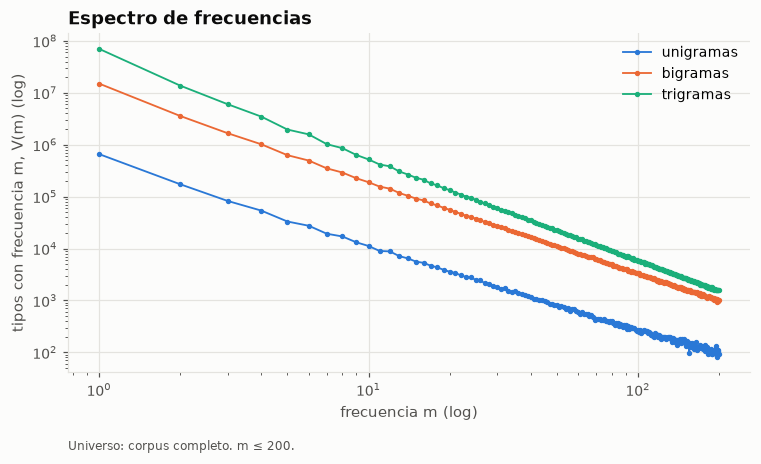

In [11]:
rows = []
for o in ("1", "2", "3"):
    a = O[o]["all"]; sp = {int(k): v for k, v in a["spectrum_le1000"].items()}
    rows.append({"orden": int(o), **{f"V({m})": sp.get(m, 0) for m in (1, 2, 3, 4, 5)},
                 "V(1)/tipos %": 100 * sp.get(1, 0) / a["types"], "V(2)/V(1)": sp.get(2, 0) / sp.get(1, 1),
                 "hapax % de ocurrencias": 100 * sp.get(1, 0) / a["tokens"]})
show(rows)
fig, ax = plt.subplots(figsize=(8, 4))
for i, o in enumerate(("1", "2", "3")):
    sp = {int(k): v for k, v in O[o]["all"]["spectrum_le1000"].items()}
    m = np.array(sorted(sp)); ax.loglog(m[m <= 200], [sp[k] for k in m[m <= 200]], marker="o", markersize=2.5,
                                        linewidth=1.2, color=viz.CATEGORICAL[i], label=names[o])
ax.set_xlabel("frecuencia m (log)"); ax.set_ylabel("tipos con frecuencia m, V(m) (log)")
ax.set_title("Espectro de frecuencias"); ax.legend()
viz.caption(ax, "Universo: corpus completo. m ≤ 200.")
viz.save(fig, FIG / "e2_espectro.png"); plt.show()

## 6. Patrón adicional: repetición y diferencias léxicas entre tags (E2-04)

### 6.1 Concentración: palabras que se repiten dentro de la misma letra

La frecuencia total mezcla dos cosas: cuántas letras usan una palabra y cuántas veces la
repiten. El cociente *ocurrencias por letra que la contiene* = `count / doc_freq` (léxico
completo) separa ambas: los estribillos y vocablos se repiten muchas veces en pocas letras.

In [12]:
conc = counts / dfreq
m = counts >= 100_000
idx = np.flatnonzero(m)
order_c = idx[np.argsort(-conc[idx])]
show([{"palabra": words[i], "frecuencia": int(counts[i]), "% de letras": 100 * dfreq[i] / D,
       "ocurrencias por letra que la usa": float(conc[i]), "vocablo": "sí" if is_voc[i] else ""} for i in order_c[:20]])
med_v = np.median(conc[m & is_voc]); med_o = np.median(conc[m & ~is_voc & ~is_stop]); med_s = np.median(conc[m & is_stop])
print(f"Mediana de ocurrencias por letra (palabras con ≥ 100 000 ocurrencias): vocablos {med_v:.2f} "
      f"(n={int((m & is_voc).sum())}), stopwords {med_s:.2f} (n={int((m & is_stop).sum())}), "
      f"resto {med_o:.2f} (n={int((m & ~is_voc & ~is_stop).sum())})")

| palabra | frecuencia | % de letras | ocurrencias por letra que la usa | vocablo |
|---|---|---|---|---|
| na | 421 775 | 1.046 | 12.775 | sí |
| i | 33 215 499 | 87.604 | 12.015 |  |
| the | 33 561 503 | 95.156 | 11.176 |  |
| you | 27 479 421 | 85.680 | 10.163 |  |
| la | 589 162 | 1.895 | 9.851 | sí |
| a | 18 094 127 | 84.647 | 6.774 |  |
| da | 337 974 | 1.585 | 6.758 | sí |
| mi | 144 491 | 0.696 | 6.577 |  |
| dey | 103 917 | 0.515 | 6.389 |  |
| to | 18 143 568 | 90.024 | 6.386 |  |
| and | 17 239 983 | 87.777 | 6.224 |  |
| my | 14 392 176 | 75.130 | 6.070 |  |
| me | 13 966 279 | 74.836 | 5.914 |  |
| i'm | 10 030 814 | 59.604 | 5.333 |  |
| it | 11 624 714 | 71.205 | 5.173 |  |
| ooh | 756 478 | 4.762 | 5.033 | sí |
| dem | 138 240 | 0.886 | 4.943 |  |
| ayy | 255 109 | 1.712 | 4.723 | sí |
| yeah | 3 977 078 | 26.845 | 4.695 | sí |
| yuh | 230 129 | 1.557 | 4.684 | sí |

Mediana de ocurrencias por letra (palabras con ≥ 100 000 ocurrencias): vocablos 4.13 (n=18), stopwords 1.88 (n=225), resto 1.69 (n=609)


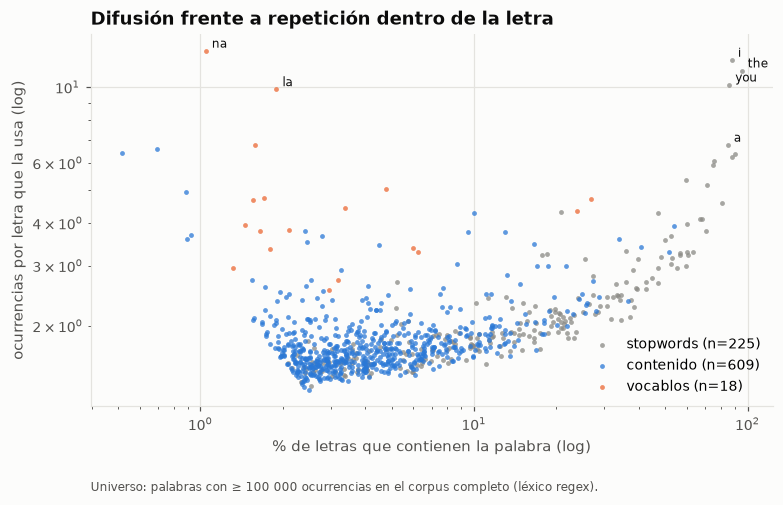

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.4))
for lab, mm, col in (("stopwords", m & is_stop, viz.MUTED), ("contenido", m & ~is_stop & ~is_voc, viz.CATEGORICAL[0]),
                     ("vocablos", m & is_voc, viz.CATEGORICAL[1])):
    ax.scatter(100 * dfreq[mm] / D, conc[mm], s=10, color=col, alpha=0.75, label=f"{lab} (n={int(mm.sum())})", linewidths=0)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("% de letras que contienen la palabra (log)"); ax.set_ylabel("ocurrencias por letra que la usa (log)")
ax.set_title("Difusión frente a repetición dentro de la letra"); ax.legend()
for i in order_c[:6]:
    ax.annotate(words[i], (100 * dfreq[i] / D, conc[i]), xytext=(4, 2), textcoords="offset points", fontsize=8, color=viz.TEXT)
viz.caption(ax, "Universo: palabras con ≥ 100 000 ocurrencias en el corpus completo (léxico regex).")
viz.save(fig, FIG / "e2_difusion_repeticion.png"); plt.show()

### 6.2 Palabras características de cada tag

Log-odds con prior de Dirichlet informativo (Monroe, Colaresi y Quinn, 2008): cada tag frente al
resto de tags, con el corpus completo como prior ($\alpha_0$ = 10 000 pseudo-conteos). Se
muestran palabras de contenido (sin stopwords ni vocablos) con ≥ 1 000 ocurrencias; el valor *z*
ordena por evidencia y no por tamaño del efecto solo. El tag es la etiqueta de la fuente, no un
género verificado.

In [14]:
vocab = [w for w, c, s, v in zip(words, counts, is_stop, is_voc) if c >= 1000 and not s and not v]
vi = {w: i for i, w in enumerate(vocab)}
Y = {t: np.zeros(len(vocab)) for t in viz.TAG_ORDER}
for g, w, c in zip(tg["group"].to_pylist(), tg["word"].to_pylist(), tg["count"].to_pylist()):
    if w in vi and g in Y: Y[g][vi[w]] += c
bg = sum(Y.values()); a0 = 10_000; alpha = a0 * bg / bg.sum()
def logodds(t):
    yi = Y[t]; yj = bg - yi; ni, nj = by[t][0], N - by[t][0]
    d = np.log((yi + alpha) / (ni + a0 - yi - alpha)) - np.log((yj + alpha) / (nj + a0 - yj - alpha))
    return d / np.sqrt(1 / (yi + alpha) + 1 / (yj + alpha)), d
LO = {t: logodds(t) for t in viz.TAG_ORDER}
show([{"tag": t, "más características (z)": ", ".join(vocab[i] for i in np.argsort(-LO[t][0])[:12])} for t in viz.TAG_ORDER])

| tag | más características (z) |
|---|---|
| pop | love, heart, away, night, tonight, eyes, gonna, baby, come, sing, dance, world |
| rap | shit, bitch, fuck, nigga, like, niggas, got, em, money, yo, gon, tryna |
| rock | away, death, blood, eyes, end, inside, fear, world, dead, burn, darkness, light |
| rb | baby, love, girl, know, wanna, babe, want, need, let, tell, right, loving |
| country | old, country, little, whiskey, town, home, beer, lonesome, cowboy, road, tennessee, long |

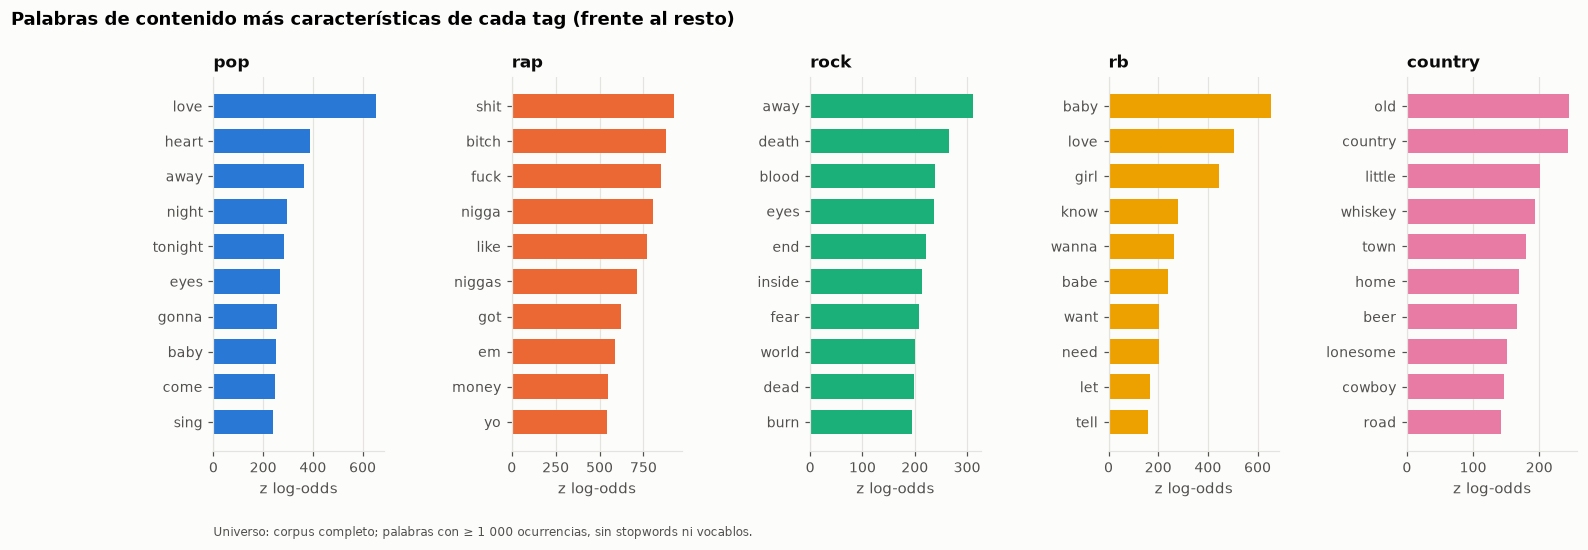

In [15]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4.6))
for ax, t in zip(axes, viz.TAG_ORDER):
    z, d = LO[t]; idx = np.argsort(-z)[:10][::-1]
    ax.barh([vocab[i] for i in idx], z[idx], color=viz.TAG_COLORS[t], height=0.7)
    ax.set_title(t, color=viz.TEXT, fontsize=11); ax.grid(axis="y", visible=False); ax.set_xlabel("z log-odds")
fig.suptitle("Palabras de contenido más características de cada tag (frente al resto)", x=0.01, ha="left", fontweight="bold")
viz.caption(axes[0], "Universo: corpus completo; palabras con ≥ 1 000 ocurrencias, sin stopwords ni vocablos.")
fig.subplots_adjust(wspace=0.75, top=0.85); viz.save(fig, FIG / "e2_logodds_tags.png"); plt.show()

## 7. Modelo de lenguaje de n-gramas con KenLM (E2-05)

| Elemento | Decisión |
|---|---|
| Implementación | KenLM `lmplz` (compilado en WSL Ubuntu 24.04; commit en `lm/results.json`) |
| Datos de ajuste | **sólo `train`**: un verso por línea, tokens regex en minúsculas |
| Fronteras | cada verso es una «oración»: `lmplz` añade `<s>` y `</s>`; no hay n-gramas entre versos |
| Vocabulario | tipos con frecuencia ≥ 2 en train; el resto (hapax de train y palabras nuevas) → clase `<oov>` en train y validation, así la perplejidad incluye todos los tokens y es comparable entre órdenes |
| Suavizado | Kneser-Ney modificado interpolado (por defecto en `lmplz`), sin poda |
| Selección | orden elegido por perplejidad en `validation`; `test` no se usa |
| Métrica | perplejidad por token incluyendo `</s>` (`query -v summary`) |

La perplejidad mide qué tan predecible es el texto para el modelo; **no** mide la calidad de una
recomendación (VAL-06).

In [16]:
res_path = NLP / "lm/results.json"
LM = json.loads(res_path.read_text(encoding="utf-8")) if res_path.exists() else {}
LM_READY = any("eval" in v for v in LM.values())
print("Resultados KenLM:", "disponibles" if LM_READY else "PENDIENTES (ngram_lm.py train/eval aún no ejecutado)")
fr = manifest["frequency"]
print("Vocabulario:", fr["lm-vocab"])
tot = fr["lm-export"]["totals"]
tr = tot["train"]; val = {k: v for k, v in tot.items() if k.startswith("validation.")}
vt = sum(v["tokens"] for v in val.values()); vo = sum(v["mapped_oov"] for v in val.values())
show([{"conjunto": "train", "letras": tr["docs"], "versos": tr["lines"], "tokens": tr["tokens"], "<oov>": tr["mapped_oov"],
       "% <oov>": 100 * tr["mapped_oov"] / tr["tokens"]},
      {"conjunto": "validation", "letras": sum(v["docs"] for v in val.values()), "versos": sum(v["lines"] for v in val.values()),
       "tokens": vt, "<oov>": vo, "% <oov>": 100 * vo / vt}])
rows = []
for key in sorted(LM, key=lambda k: int(k[1:])) if LM_READY else []:
    e = LM[key]
    if "eval" not in e: continue
    rows.append({"orden": e["train"]["order"], **{f"{n}-gramas": e["train"]["ngram_counts"].get(f"{n}-gram", 0) for n in range(1, 5)},
                 "binario MB": e["train"]["files_bytes"].get(f"{key}.binary", 0) / 2**20,
                 "PPL validation": e["eval"]["validation"]["ppl_incl_oov"],
                 "OOV KenLM": e["eval"]["validation"]["kenlm_oovs"]})
if rows:
    show(rows)
    best = min(rows, key=lambda r: r["PPL validation"]); BEST = f"o{best['orden']}"
    print("Orden elegido por validation:", best["orden"])

Resultados KenLM: PENDIENTES (ngram_lm.py train/eval aún no ejecutado)
Vocabulario: {'min_count': 2, 'types': 497831, 'train_tokens_covered': 631139981, 'path': 'data/processed/nlp/lyrics_full_v1/lm/vocab_train_min2.txt', 'finished_utc': '2026-11-15T00:56:30+00:00'}


| conjunto | letras | versos | tokens | <oov> | % <oov> |
|---|---|---|---|---|---|
| train | 2 208 832 | 91 731 600 | 631 669 490 | 529 509 | 0.084 |
| validation | 315 289 | 13 085 181 | 90 048 892 | 168 646 | 0.187 |

In [17]:
if LM_READY:
    ev = LM[BEST]["eval"]
    show([{"tag": t, "tokens (incl. </s>)": ev[f"validation.{t}"]["tokens_incl_eos"],
           "PPL": ev[f"validation.{t}"]["ppl_incl_oov"]} for t in viz.TAG_ORDER])
    fig, ax = plt.subplots(figsize=(8, 3.8))
    for i, key in enumerate(sorted((k for k in LM if "eval" in LM[k]), key=lambda k: int(k[1:]))):
        vals = [LM[key]["eval"][f"validation.{t}"]["ppl_incl_oov"] for t in viz.TAG_ORDER]
        ax.plot(viz.TAG_ORDER, vals, marker="o", color=viz.CATEGORICAL[i], label=f"orden {key[1:]}")
    ax.set_ylabel("perplejidad en validation"); ax.set_title("Perplejidad por tag y orden del modelo"); ax.legend()
    viz.caption(ax, "Modelo aprendido sólo con train; evaluado en todas las letras de validation de cada tag.")
    viz.save(fig, FIG / "e2_perplejidad_tags.png"); plt.show()
else:
    print("Pendiente: requiere los resultados de KenLM.")

Pendiente: requiere los resultados de KenLM.


In [18]:
if LM_READY:
    # Ejemplos ilustrativos (frases construidas a mano, no del corpus): log10 P por token.
    ex = LM[BEST].get("examples", [])
    for e in ex:
        print(f"{e['total_log10']:8.2f}  {e['sentence']}")
else:
    print("Pendiente: requiere los resultados de KenLM.")

Pendiente: requiere los resultados de KenLM.


## 8. Hallazgos e interpretación

Todas las cifras proceden de las celdas anteriores (corpus completo salvo que se indique).

1. **Universo reconciliado.** 902 376 353 tokens regex y 1 277 145 tipos; los totales por split
   (train 631 669 490 · validation 90 048 892 · test 180 657 971) y por tag coinciden exactamente
   con el léxico y con el conteo de n-gramas, así que todas las tablas comparten denominador.

2. **Las palabras funcionales dominan la frecuencia, no el vocabulario.** Las 326 stopwords de
   spaCy más 807 contracciones formadas sólo por ellas (`i'm`, `don't`, `can't`…) suman el 56,6 %
   de los tokens; las diez palabras más frecuentes cubren el 22,1 %. Sin ellas aparece el
   contenido propio del género: `like` (en el 53,9 % de las letras), `know`, `got`, `love`,
   `time`, `want`, `baby`, `life`. Sin ampliar la lista con contracciones, `i'm` y `don't`
   encabezaban falsamente el top «de contenido»: la política de stopwords debe ajustarse a la
   tokenización usada.

3. **Vocablos: un 1,7 % de los tokens, muy desigual entre tags.** La lista (424 formas, derivada
   sólo de train y revisada) suma 15 442 494 tokens. El POS de spaCy no basta para encontrarlos:
   `ooh`, `la` y `na` se etiquetan mayoritariamente como `PROPN`/`PART` y se recuperaron por
   autorrepetición (`na na`). El R&B usa 29,2 vocablos por cada 1 000 tokens, el pop 19,5, el rap
   15,6 y rock y country unos 12,5–12,7; el rap tiene además menos palabras funcionales (54,0 %
   frente a 58,6–59,2 %), coherente con versos más densos léxicamente.

4. **n-gramas: la repetición domina el extremo frecuente.** Los tipos pasan de 1,28 M (orden 1) a
   25,9 M y 105,3 M; los hapax son el 51,6 %, 58,1 % y 66,7 % de los tipos, y en trigramas
   suponen ya el 10,9 % de las ocurrencias (dispersión que el modelo de lenguaje deberá
   suavizar). Cuatro de los seis trigramas más frecuentes son vocablos repetidos
   (`oh oh oh` 450 177, `la la la`, `yeah yeah yeah`, `na na na`). Al filtrar, los bigramas de
   contenido son colocaciones (`feel like` 328 820, `far away`, `brand new`, `run away`) y los
   trigramas de contenido vuelven a ser repeticiones de palabras léxicas (`love love love`,
   `baby baby baby`, `money money money`).

5. **Zipf aproxima, pero no se cumple como ley exacta.** Una recta sobre los rangos 1–197 878
   (frecuencia ≥ 10) da α = 1,36 con R² = 0,978, pero los residuos forman un arco sistemático:
   las diez palabras más frecuentes quedan a 0,27 veces del ajuste, los rangos 10–100 000 un
   ~20 % por encima y la cola (> 100 000) a 0,34 veces. En el tramo central (10–10 000) α = 1,23
   (R² 0,992), más empinado que el α ≈ 1 clásico; Zipf–Mandelbrot (b ≈ 39) absorbe la cabeza
   plana y sube a R² 0,995. Bigramas y trigramas son más planos (α central 0,74 y 0,55). El
   espectro confirma la cola larga: V(1) = 659 589 tipos hapax (51,6 %) y V(2)/V(1) = 0,26.

6. **Patrón adicional (E2-04): frecuencia ≠ difusión.** Los vocablos se concentran en pocas
   letras que los repiten mucho: `na` aparece en el 1,05 % de las letras, pero 12,8 veces en cada
   una; `la` 9,9 y `da` 6,8 veces. Entre las palabras con ≥ 100 000 ocurrencias, la mediana de
   ocurrencias por letra es 4,13 para vocablos, 1,88 para stopwords y 1,69 para el resto. Es la
   huella cuantitativa del estribillo: una frecuencia bruta alta puede venir de pocas canciones.
   Para los modelos de E5 esto justifica una tf sublineal o binaria y usar la frecuencia
   documental, no sólo la total. Formas criollas como `dey`, `dem` o `mi` muestran la misma
   concentración.

7. **Diferencias léxicas entre tags.** Con log-odds y prior de Dirichlet: country = `old`,
   `whiskey`, `town`, `beer`, `cowboy`, `tennessee` (lugar y vida rural); rock = `death`,
   `blood`, `fear`, `darkness`, `burn`; rap = palabras malsonantes, insultos raciales
   reapropiados y `money`; R&B = `baby`, `love`, `girl`, `babe`; pop = `love`, `heart`,
   `night`, `tonight`, `dance`. Son contrastes contra «el resto», dominado por pop (42 % de las
   letras), y el tag es la etiqueta de la fuente, no un género verificado.

8. **Limitaciones.** (a) La lista de vocablos es heurística: formas ambiguas con uso léxico
   (`aye`, `ya`, `yo`, `yea`, `o`) quedaron fuera a propósito y aparecen en los trigramas de
   contenido; (b) los tokens regex no separan contracciones, a diferencia de spaCy (E3), por lo
   que las cifras de ambos no son directamente comparables; (c) spaCy `en_core_web_sm` comete
   errores de POS en vocablos (los etiqueta como nombres propios), lo que se analizará en E3;
   (d) el modelo de lenguaje (sección 7) depende de KenLM en WSL y sus resultados se reportan
   sólo cuando `pipelines/nlp/ngram_lm.py` termina; mientras falten, la sección 7 lo indica
   explícitamente.